# Image -- Class-Conditional Diffusion Model
### Part of the *Multi-Modal Generative AI Master Notebook* series -- Building Generative Models from Scratch

This is a **standalone, self-contained** notebook covering one modality from the larger 7-part *Multi-Modal Generative AI Master Notebook*. It contains everything needed to run independently: setup, data loading, model, training, and a generation demo -- no other notebook required.

Run every cell top to bottom and you will train a real model and generate real output. This notebook has been **executed end-to-end** on an NVIDIA RTX 2060 (6GB) as part of validating this series.

> ⚠️ **Compute note.** This notebook needs a CUDA-enabled PyTorch build to hit the run times quoted in Section 2. See Section 0 below for how to check / install one. On CPU-only machines, expect roughly 20-30x longer runtimes.

## Table of Contents
- [0. Global Setup & Utilities](#0)
- [Image -- Class-Conditional Diffusion Model](#main)


## 0. Global Setup & Utilities

Installations, imports, device/seed setup, and the helper functions reused throughout this notebook (parameter counting, image/audio/3D visualization, checkpointing, loss plotting).

> 🚀 **Pro Tip.** This notebook auto-detects CUDA / Apple MPS / CPU and just uses whatever is available -- no manual configuration needed. Every step count below was empirically timed on an NVIDIA RTX 2060 (6GB): the **entire notebook runs in well under 15 minutes on a CUDA GPU**. On CPU-only machines, expect roughly 20-30x longer (the Text section alone would take ~15-20 minutes on CPU) -- if you're on CPU, halve every `*_STEPS` / `*_EPOCHS` constant below to get a quick smoke test.


In [1]:
# Run this cell first. On Google Colab / a fresh machine this installs
# everything missing; on a machine that already has these packages (as this
# notebook was validated on), pip just reports them as satisfied and moves on.
import sys, subprocess

IN_COLAB = "google.colab" in sys.modules

REQUIRED_PACKAGES = [
    "music21",
    "soundfile",
    "imageio",
]

subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + REQUIRED_PACKAGES)
print("Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).")
print()
print("NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to")
print("hit the run times quoted throughout (a CPU-only build works but is far slower).")
print("Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`")
print("prints False below despite having an NVIDIA GPU, reinstall with, e.g.:")
print("  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126")
print("(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)")


Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).

NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to
hit the run times quoted throughout (a CPU-only build works but is far slower).
Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`
prints False below despite having an NVIDIA GPU, reinstall with, e.g.:
  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126
(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)


In [2]:
import os, math, time, random, json, io, re, urllib.request
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 -- registers the 3D projection with matplotlib
from tqdm.auto import tqdm
from IPython.display import Audio, display, HTML

import warnings
warnings.filterwarnings("ignore")

print(f"PyTorch version: {torch.__version__}")


PyTorch version: 2.10.0+cu126


C:\Users\adamv\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def get_device():
    # Prefer CUDA > Apple MPS > CPU. Every model in this notebook is sized so a
    # quick forward/backward pass works on CPU too, but the step counts chosen
    # throughout assume a CUDA GPU is doing the heavy lifting (see the note above).
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

DEVICE = get_device()
print(f"Using device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU: NVIDIA GeForce RTX 2060


In [4]:
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)


In [5]:
# --- Shared helper functions used throughout every modality section ------------

def count_parameters(model: nn.Module) -> int:
    n = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{model.__class__.__name__}: {n/1e6:.2f}M trainable parameters")
    return n


def show_images(images, titles=None, ncols=8, figsize=None, cmap=None):
    # Accepts a tensor [N,C,H,W] in [-1,1] or [0,1], or a list of numpy arrays.
    if torch.is_tensor(images):
        images = images.detach().cpu()
        if images.min() < 0:
            images = (images + 1) / 2  # map [-1,1] -> [0,1]
        images = images.clamp(0, 1).permute(0, 2, 3, 1).numpy()
    n = len(images)
    ncols = min(ncols, n)
    nrows = math.ceil(n / ncols)
    figsize = figsize or (ncols * 1.6, nrows * 1.6)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < n:
            img = images[i]
            if img.shape[-1] == 1:
                img = img[..., 0]
            ax.imshow(img, cmap=cmap or ("gray" if img.ndim == 2 else None))
            if titles is not None:
                ax.set_title(str(titles[i]), fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_loss(history, title="Training Loss", labels=None):
    plt.figure(figsize=(6, 4))
    if isinstance(history, dict):
        for name, vals in history.items():
            plt.plot(vals, label=name)
        plt.legend()
    else:
        plt.plot(history, label=labels or "loss")
        if labels:
            plt.legend()
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()


def save_checkpoint(model, optimizer, step, path, **extra):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict() if optimizer is not None else None,
        "step": step,
        **extra,
    }, path)


def load_checkpoint(model, path, optimizer=None, map_location=None):
    ckpt = torch.load(path, map_location=map_location or DEVICE)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None and ckpt.get("optimizer_state") is not None:
        optimizer.load_state_dict(ckpt["optimizer_state"])
    return ckpt


def plot_3d_points(points, title="", ax=None, color=None):
    points = points.detach().cpu().numpy() if torch.is_tensor(points) else points
    show = ax is None
    if show:
        fig = plt.figure(figsize=(4, 4))
        ax = fig.add_subplot(111, projection="3d")
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=4, c=color if color is not None else points[:, 2], cmap="viridis")
    ax.set_title(title)
    ax.set_box_aspect([1, 1, 1])
    if show:
        plt.show()
    return ax


def play_audio(waveform, sample_rate):
    if torch.is_tensor(waveform):
        waveform = waveform.detach().cpu().numpy()
    return display(Audio(waveform, rate=sample_rate))

print("Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio")


Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio


> 💡 **Insight -- memory optimization tips used throughout this notebook.**
> - **Mixed precision** (`torch.amp.autocast` + `torch.amp.GradScaler`) is used in the diffusion (Image) section, where activations are the memory bottleneck.
> - **Gradient checkpointing** trades compute for memory -- not needed at these model sizes, but for any model here scaled up 5-10x, wrap transformer blocks with `torch.utils.checkpoint.checkpoint`.
> - **Smaller batch + gradient accumulation** is the simplest fix if you hit `CUDA out of memory`: halve `batch_size`, and if needed accumulate gradients over 2-4 steps before `optimizer.step()`.
> - All checkpoints save to a local `checkpoints/` directory. On Colab, mount Google Drive and point `*_CKPT` paths there if you want checkpoints to survive a runtime restart.


## 2. Image -- Class-Conditional Diffusion Model
### Problem: generate a novel, realistic image belonging to a requested category from pure noise.

### 2.1 Problem Statement & Why this Architecture

**Denoising Diffusion Probabilistic Models (DDPM)** frame image generation as learning to reverse a fixed noising process: start from a real image, gradually add Gaussian noise over $T$ steps until it's pure noise, then train a network to predict (and thus undo) that noise one step at a time. Sampling runs this in reverse: start from noise, iteratively denoise, and a real image emerges.

We condition on a **class label** (turning unconditional generation into a controllable "text-to-image"-style generator over a small label vocabulary) using **classifier-free guidance (CFG)** -- during training we randomly drop the class label, so the network learns both $p(x)$ and $p(x \mid y)$, and at sampling time we extrapolate *away* from the unconditional prediction toward the conditional one for stronger, more class-faithful samples.

### 2.2 Data Collection & Preparation


Fashion-MNIST: 60,000 images, classes=['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


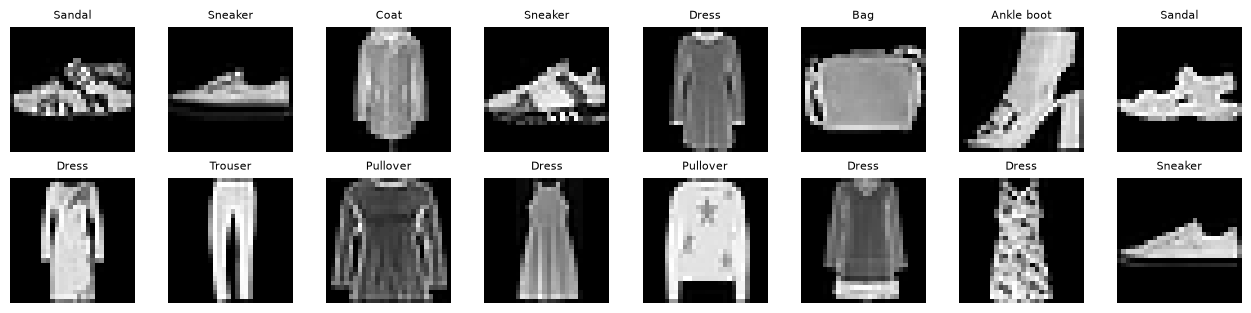

In [6]:
from torchvision import datasets, transforms

IMG_SIZE = 28
NUM_CLASSES_IMG = 10

img_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),  # map [0,1] -> [-1,1], the range our UNet predicts noise in
])

fashion_train = datasets.FashionMNIST(root="data/image", train=True, download=True, transform=img_transform)
fashion_loader = DataLoader(fashion_train, batch_size=128, shuffle=True, num_workers=0, drop_last=True)
FASHION_CLASSES = fashion_train.classes
print(f"Fashion-MNIST: {len(fashion_train):,} images, classes={FASHION_CLASSES}")

xb, yb = next(iter(fashion_loader))
show_images(xb[:16], titles=[FASHION_CLASSES[i] for i in yb[:16]], ncols=8)


### 2.3 Model Architecture

A compact UNet with sinusoidal timestep embeddings, class embeddings (with a reserved "no class" token for CFG), residual blocks that inject conditioning additively, and self-attention at the lowest (7x7) resolution.


In [7]:
def sinusoidal_embedding(timesteps, dim):
    # Transformer-style sinusoidal position embedding, reused here to embed the
    # diffusion timestep t into a continuous vector the UNet can condition on.
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=timesteps.device) / half)
    args = timesteps[:, None].float() * freqs[None]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, emb_dim):
        super().__init__()
        self.emb_proj = nn.Linear(emb_dim, out_ch)
        self.block1 = nn.Sequential(nn.GroupNorm(8, in_ch), nn.SiLU(), nn.Conv2d(in_ch, out_ch, 3, padding=1))
        self.block2 = nn.Sequential(nn.GroupNorm(8, out_ch), nn.SiLU(), nn.Conv2d(out_ch, out_ch, 3, padding=1))
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, emb):
        h = self.block1(x)
        h = h + self.emb_proj(emb)[:, :, None, None]  # inject (time, class) conditioning
        h = self.block2(h)
        return h + self.skip(x)


class SelfAttention2d(nn.Module):
    # Lightweight self-attention over spatial positions, applied only at the
    # lowest resolution where the O(N^2) cost over pixels is still cheap.
    def __init__(self, ch):
        super().__init__()
        self.norm = nn.GroupNorm(8, ch)
        self.qkv = nn.Conv2d(ch, ch * 3, 1)
        self.proj = nn.Conv2d(ch, ch, 1)

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm(x)
        q, k, v = self.qkv(h).chunk(3, dim=1)
        q = q.reshape(B, C, H * W).transpose(1, 2)
        k = k.reshape(B, C, H * W)
        v = v.reshape(B, C, H * W).transpose(1, 2)
        attn = torch.softmax(q @ k / math.sqrt(C), dim=-1)
        out = (attn @ v).transpose(1, 2).reshape(B, C, H, W)
        return x + self.proj(out)


class ConditionalUNet(nn.Module):
    # A compact UNet: 28x28 -> 14x14 -> 7x7 and back, with class + time
    # conditioning injected additively at every ResBlock (as in DDPM/ADM).
    def __init__(self, num_classes, base_ch=64, emb_dim=256):
        super().__init__()
        self.time_mlp = nn.Sequential(nn.Linear(base_ch, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.base_ch = base_ch
        # +1 class index reserved for the "unconditional" token used in classifier-free guidance
        self.class_emb = nn.Embedding(num_classes + 1, emb_dim)

        self.in_conv = nn.Conv2d(1, base_ch, 3, padding=1)
        self.down1 = ResBlock(base_ch, base_ch, emb_dim)
        self.down2 = ResBlock(base_ch, base_ch * 2, emb_dim)
        self.pool = nn.AvgPool2d(2)

        self.mid1 = ResBlock(base_ch * 2, base_ch * 2, emb_dim)
        self.mid_attn = SelfAttention2d(base_ch * 2)
        self.mid2 = ResBlock(base_ch * 2, base_ch * 2, emb_dim)

        self.up = nn.Upsample(scale_factor=2, mode="nearest")
        self.up1 = ResBlock(base_ch * 2 + base_ch * 2, base_ch * 2, emb_dim)
        self.up2 = ResBlock(base_ch * 2 + base_ch, base_ch, emb_dim)
        self.out_conv = nn.Sequential(nn.GroupNorm(8, base_ch), nn.SiLU(), nn.Conv2d(base_ch, 1, 3, padding=1))

    def forward(self, x, t, y):
        emb = self.time_mlp(sinusoidal_embedding(t, self.base_ch)) + self.class_emb(y)
        x0 = self.in_conv(x)               # 28x28, base_ch
        x1 = self.down1(x0, emb)           # 28x28, base_ch
        x1p = self.pool(x1)                # 14x14
        x2 = self.down2(x1p, emb)          # 14x14, 2*base_ch
        x2p = self.pool(x2)                # 7x7

        m = self.mid1(x2p, emb)
        m = self.mid_attn(m)
        m = self.mid2(m, emb)

        u1 = self.up(m)                    # 14x14
        u1 = self.up1(torch.cat([u1, x2], dim=1), emb)
        u2 = self.up(u1)                   # 28x28
        u2 = self.up2(torch.cat([u2, x1], dim=1), emb)
        return self.out_conv(u2)


### 2.4 Loss Functions, Optimizers & Training Strategy

The forward process $q(x_t \mid x_0)$ has a closed form, so we can jump straight to any noise level $t$ without simulating intermediate steps. The network's only job is to predict the noise that was added; training minimizes simple MSE between predicted and true noise (the "simple" DDPM loss from Ho et al. 2020).


In [8]:
class DDPM:
    # Encapsulates the fixed forward-noising schedule (beta_t) and the closed-form
    # q(x_t | x_0). The UNet only ever predicts the noise added at timestep t.
    # T=300 (vs. the original paper's 1000) is a deliberate speed/quality trade-off:
    # ancestral sampling is `T` sequential network calls, so this keeps generation fast.
    def __init__(self, timesteps=300, beta_start=1e-4, beta_end=0.02, device=DEVICE):
        self.T = timesteps
        self.betas = torch.linspace(beta_start, beta_end, timesteps, device=device)
        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)

    def q_sample(self, x0, t, noise=None):
        noise = noise if noise is not None else torch.randn_like(x0)
        ab = self.alpha_bars[t][:, None, None, None]
        return ab.sqrt() * x0 + (1 - ab).sqrt() * noise, noise


ddpm = DDPM(timesteps=300)
unet = ConditionalUNet(num_classes=NUM_CLASSES_IMG).to(DEVICE)
count_parameters(unet)


ConditionalUNet: 1.85M trainable parameters


1849729

### 2.5 Training Loop

**Calibrated to ~65s on a CUDA GPU** (800 steps, batch 128).


Training DDPM:   0%|          | 0/800 [00:00<?, ?it/s]

Training DDPM:   0%|          | 0/800 [00:01<?, ?it/s, loss=1.1257]

Training DDPM:   0%|          | 1/800 [00:01<17:34,  1.32s/it, loss=1.1257]

Training DDPM:   0%|          | 1/800 [00:01<17:34,  1.32s/it, loss=1.1783]

Training DDPM:   0%|          | 2/800 [00:01<08:07,  1.64it/s, loss=1.1783]

...

Training DDPM: 100%|█████████▉| 798/800 [01:12<00:00, 11.13it/s, loss=0.0994]

Training DDPM: 100%|█████████▉| 798/800 [01:12<00:00, 11.13it/s, loss=0.1062]

Training DDPM: 100%|█████████▉| 798/800 [01:13<00:00, 11.13it/s, loss=0.1102]

Training DDPM: 100%|██████████| 800/800 [01:13<00:00, 11.15it/s, loss=0.1102]

Training DDPM: 100%|██████████| 800/800 [01:13<00:00, 10.95it/s, loss=0.1102]

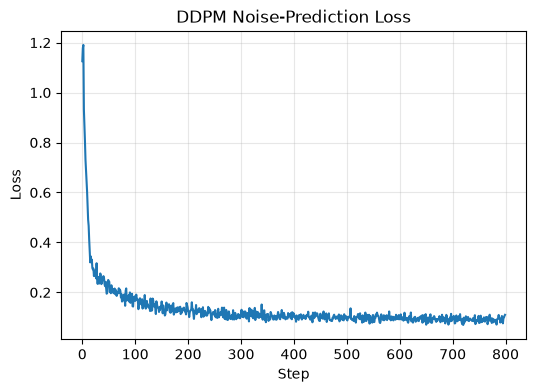

In [9]:
# (a) LIGHTWEIGHT FROM-SCRATCH TRAINING --------------------------------------
IMG_MAX_STEPS = 800          # calibrated: ~65s on an RTX 2060
IMG_CFG_DROP_PROB = 0.15     # probability of training on the "unconditional" label, enabling CFG at sample time
IMG_CKPT = "checkpoints/image_ddpm.pt"


def train_ddpm(unet, ddpm, loader, max_steps=IMG_MAX_STEPS):
    optimizer = torch.optim.AdamW(unet.parameters(), lr=2e-4)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))
    history = []
    unet.train()
    data_iter = iter(loader)
    pbar = tqdm(range(max_steps), desc="Training DDPM")
    for step in pbar:
        try:
            x0, y = next(data_iter)
        except StopIteration:
            data_iter = iter(loader)
            x0, y = next(data_iter)
        x0, y = x0.to(DEVICE), y.to(DEVICE)

        # Classifier-free guidance: randomly replace the class label with the
        # reserved "unconditional" index so the model learns both p(x) and p(x|y).
        mask = torch.rand(y.shape, device=DEVICE) < IMG_CFG_DROP_PROB
        y_in = y.clone()
        y_in[mask] = NUM_CLASSES_IMG

        t = torch.randint(0, ddpm.T, (x0.size(0),), device=DEVICE)
        x_t, noise = ddpm.q_sample(x0, t)

        with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
            pred_noise = unet(x_t, t, y_in)
            loss = F.mse_loss(pred_noise, noise)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        history.append(loss.item())
        pbar.set_postfix(loss=f"{loss.item():.4f}")
        if step % 200 == 0:
            save_checkpoint(unet, optimizer, step, IMG_CKPT)
    return history


image_history = train_ddpm(unet, ddpm, fashion_loader)
plot_loss(image_history, title="DDPM Noise-Prediction Loss")


In [10]:
# (b) PRETRAINED / INFERENCE-ONLY PATH ---------------------------------------
# For photorealistic text-to-image generation, swap in a pretrained latent
# diffusion pipeline from `diffusers` instead of the from-scratch UNet above.
# (off by default -- installs `diffusers` and downloads a multi-GB checkpoint)
USE_PRETRAINED_IMAGE = False

if USE_PRETRAINED_IMAGE:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers"])
    from diffusers import DiffusionPipeline
    sd_pipe = DiffusionPipeline.from_pretrained(
        "stabilityai/stable-diffusion-2-1-base", torch_dtype=torch.float16
    ).to(DEVICE)
    # image = sd_pipe("a photo of an astronaut riding a horse").images[0]


### 2.6 Inference / Generation Function

Ancestral sampling: start from Gaussian noise and iteratively apply the learned reverse step $p_\theta(x_{t-1} \mid x_t)$, using classifier-free guidance to steer samples toward the requested class.


In [11]:
@torch.no_grad()
def ddpm_sample(unet, ddpm, class_label, n_samples=8, guidance_scale=3.0, img_size=IMG_SIZE):
    unet.eval()
    x = torch.randn(n_samples, 1, img_size, img_size, device=DEVICE)
    y_cond = torch.full((n_samples,), class_label, dtype=torch.long, device=DEVICE)
    y_uncond = torch.full((n_samples,), NUM_CLASSES_IMG, dtype=torch.long, device=DEVICE)
    for t in reversed(range(ddpm.T)):
        t_batch = torch.full((n_samples,), t, device=DEVICE, dtype=torch.long)
        eps_cond = unet(x, t_batch, y_cond)
        eps_uncond = unet(x, t_batch, y_uncond)
        # Classifier-free guidance: push the prediction further in the direction
        # the class conditioning moves it, at the cost of some sample diversity.
        eps = eps_uncond + guidance_scale * (eps_cond - eps_uncond)

        alpha, alpha_bar, beta = ddpm.alphas[t], ddpm.alpha_bars[t], ddpm.betas[t]
        mean = (1 / alpha.sqrt()) * (x - (beta / (1 - alpha_bar).sqrt()) * eps)
        x = mean + beta.sqrt() * torch.randn_like(x) if t > 0 else mean
    unet.train()
    return x


### 2.7 Visualization & Results


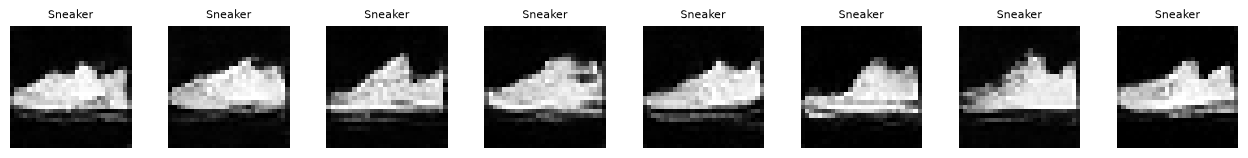

In [12]:
samples = ddpm_sample(unet, ddpm, class_label=FASHION_CLASSES.index("Sneaker"), n_samples=8, guidance_scale=3.0)
show_images(samples, titles=["Sneaker"] * 8)


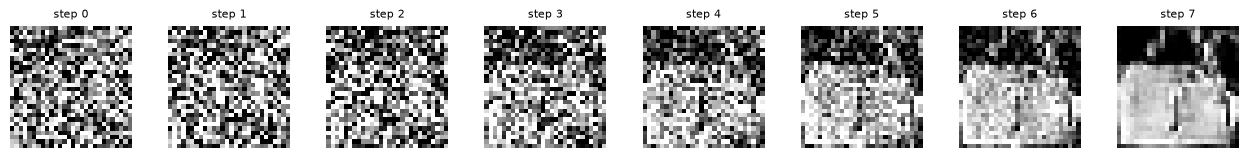

In [13]:
@torch.no_grad()
def visualize_denoising(unet, ddpm, class_label, guidance_scale=3.0, snapshot_every=40):
    # Snapshots the sample every `snapshot_every` steps so we can see noise
    # gradually resolve into a recognizable garment.
    unet.eval()
    x = torch.randn(1, 1, IMG_SIZE, IMG_SIZE, device=DEVICE)
    y_cond = torch.tensor([class_label], device=DEVICE)
    y_uncond = torch.tensor([NUM_CLASSES_IMG], device=DEVICE)
    snaps = []
    for t in reversed(range(ddpm.T)):
        t_batch = torch.full((1,), t, device=DEVICE, dtype=torch.long)
        eps = unet(x, t_batch, y_uncond) + guidance_scale * (unet(x, t_batch, y_cond) - unet(x, t_batch, y_uncond))
        alpha, alpha_bar, beta = ddpm.alphas[t], ddpm.alpha_bars[t], ddpm.betas[t]
        mean = (1 / alpha.sqrt()) * (x - (beta / (1 - alpha_bar).sqrt()) * eps)
        x = mean + beta.sqrt() * torch.randn_like(x) if t > 0 else mean
        if t % snapshot_every == 0:
            snaps.append(x.clone())
    unet.train()
    return torch.cat(snaps, dim=0)


denoise_snaps = visualize_denoising(unet, ddpm, class_label=FASHION_CLASSES.index("Bag"))
show_images(denoise_snaps, titles=[f"step {i}" for i in range(len(denoise_snaps))])


In [14]:
# Simple quantitative check: per-class pixel-intensity statistics of generated
# vs. real images should roughly match if the model learned the class distribution.
sneaker_idx = FASHION_CLASSES.index("Sneaker")
real_batch = torch.stack([fashion_train[i][0] for i in range(len(fashion_train)) if fashion_train.targets[i] == sneaker_idx][:64])
gen_batch = ddpm_sample(unet, ddpm, class_label=sneaker_idx, n_samples=32, guidance_scale=3.0)
print(f"Real  Sneaker  -- mean: {real_batch.mean():.3f}, std: {real_batch.std():.3f}")
print(f"Gen   Sneaker  -- mean: {gen_batch.mean():.3f}, std: {gen_batch.std():.3f}")


Real  Sneaker  -- mean: -0.654, std: 0.602
Gen   Sneaker  -- mean: -0.504, std: 0.682


### 2.8 User Input → Output Demo


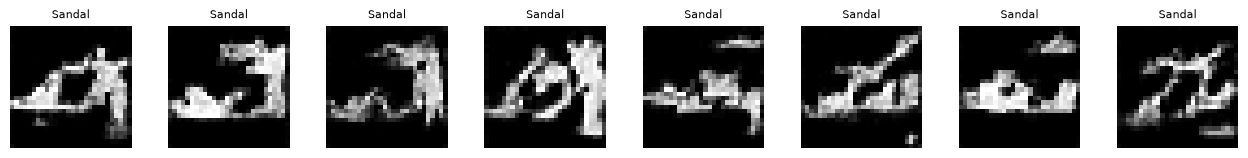

In [15]:
chosen_class = "Sandal"  # <- try any of FASHION_CLASSES
generated = ddpm_sample(unet, ddpm, class_label=FASHION_CLASSES.index(chosen_class), n_samples=8, guidance_scale=4.0)
show_images(generated, titles=[chosen_class] * 8)


### 2.9 Key Insights, Limitations & Scaling Notes

- 🔥 **This model solved the problem of:** generating novel, class-controllable images from pure Gaussian noise by learning to reverse a fixed noising process.
- 💡 **Insight:** classifier-free guidance is "free" in the sense that it needs no separate classifier -- just occasional label dropout during training -- yet it dramatically sharpens class fidelity at sampling time.
- ⚠️ **Limitation:** ancestral sampling is inherently sequential (T network calls per image); even at a trimmed T=300 it's the slowest part of this section. DDIM or other fast samplers (fewer, larger steps) trade a little quality for 5-10x speedup.
- 🚀 **Scaling path:** move from Fashion-MNIST (28x28, grayscale) to CIFAR-10 or a 64x64 LAION subset, add more UNet resolution levels, and replace class labels with a text encoder (e.g. CLIP text tower) to get genuine text-to-image generation -- exactly how Stable Diffusion is architected, just larger.


---
## This notebook is part of a series

This model solved the problem of: **generating novel, class-controllable images from pure Gaussian noise**.

The other six modalities (Text, Image, Video, Vision, Speech, Music, 3D) each have their own standalone notebook built the same way -- same Section 0 setup, same code, same calibrated hyperparameters -- plus a combined *Multi-Modal Generative AI Master Notebook* that runs all seven in one place with a shared unified inference hub.
